<div style="border-top:5px solid #8b5aab;padding:24px 28px;background:#f6f1fa;color:#38234d;border-radius:6px;">
<p style="color:#8b5aab;letter-spacing:2px;font-size:12px;margin:0;">UNIVERSITY OF TEHRAN</p>
<h1 style="color:#38234d;margin:12px 0 6px;">Fundamentals of Computer Vision</h1>
<p style="font-size:19px;margin:0 0 18px;">Computer Assignment 1 · Question 3</p>
<p style="margin:0 0 18px;color:#73617f;">Video processing and restoration<br>Fall semester · 1405–1406</p>
<table style="border-collapse:collapse;text-align:left;background:transparent;">
<thead><tr><th style="padding:8px 30px 8px 0;">Group members</th><th style="padding:8px 0;">Student number</th></tr></thead>
<tbody><tr><td style="padding:7px 30px 7px 0;">Mohammad Amin Jangi</td><td>810102429</td></tr>
<tr><td style="padding:7px 30px 7px 0;">Narges Jafari</td><td>810101601</td></tr></tbody>
</table>
</div>

---

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

In [2]:
video_path = Path("HW1_Files") / "park_video.mp4"
output_dir = Path("outputs") / "Q3"
output_dir.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.titlecolor": "#38234d",
    "axes.titlesize": 13,
    "font.size": 11,
    "savefig.facecolor": "white",
})

<hr>
<h2 style="color:#38234d;border-left:4px solid #8b5aab;padding-left:12px;">3.1 · Video loading and properties</h2>
<p>We open <code>park_video.mp4</code> with OpenCV and read its stored frame count, frame rate, and frame dimensions. The duration is calculated by dividing the number of frames by the frame rate.</p>

In [3]:
video = cv2.VideoCapture(str(video_path))

frame_count = int(video.get(cv2.CAP_PROP_FRAME_COUNT))
fps = video.get(cv2.CAP_PROP_FPS)
frame_width = int(video.get(cv2.CAP_PROP_FRAME_WIDTH))
frame_height = int(video.get(cv2.CAP_PROP_FRAME_HEIGHT))
duration = frame_count / fps

video.release()

In [4]:
print(f"Video: {video_path.name}")
print(f"Total frames: {frame_count}")
print(f"Frame rate: {fps:.2f} FPS")
print(f"Frame dimensions (width × height): {frame_width} × {frame_height} pixels")
print(f"Duration: {duration:.2f} seconds")

Video: park_video.mp4
Total frames: 450
Frame rate: 30.00 FPS
Frame dimensions (width × height): 1280 × 720 pixels
Duration: 15.00 seconds


<h3 style="color:#8b5aab;">Report · Method and results</h3>
<table>
<thead><tr><th>Property</th><th>Result</th></tr></thead>
<tbody>
<tr><td>Total frame count</td><td>450 frames</td></tr>
<tr><td>Frame rate</td><td>30.00 frames per second</td></tr>
<tr><td>Frame dimensions (width × height)</td><td>1280 × 720 pixels</td></tr>
<tr><td>Duration</td><td>15.00 seconds</td></tr>
</tbody>
</table>
<p>The video contains 450 frames played at 30 frames per second, giving a duration of <b>450 / 30 = 15 seconds</b>. Each frame is an image with 1280 columns and 720 rows. The frame rate controls how many images are shown each second, while the dimensions describe the spatial resolution of each image.</p>
<p><code>VideoCapture</code> opens the video, and <code>get</code> retrieves the requested properties. Frame count and dimensions are converted to integers because they describe whole frames and pixels; FPS is kept as a floating-point value because frame rates need not be integers. <code>release()</code> closes the video after reading its properties. The measured frame rate and dimensions will be used for the output videos so that their timing and resolution are preserved.</p>

<hr>
<h2 style="color:#38234d;border-left:4px solid #8b5aab;padding-left:12px;">3.2 · Adding salt-and-pepper noise</h2>
<p>Salt-and-pepper noise replaces individual pixels with black (pepper) or white (salt). We select <b>5% of the pixel positions in each frame</b>, without repetition, and split them equally between black and white. All three color channels at a selected position receive the same value, producing black/white dots rather than colored dots.</p>

In [5]:
noise_density = 0.05
random_number_generator = np.random.default_rng(42)


def add_salt_and_pepper(frame):
    height, width = frame.shape[:2]
    number_of_noisy_pixels = int(round(noise_density * height * width))
    positions = random_number_generator.choice(height * width, size=number_of_noisy_pixels, replace=False)
    rows, columns = np.unravel_index(positions, (height, width))
    pepper_count = number_of_noisy_pixels // 2

    noisy_frame = frame.copy()
    noisy_frame[rows[:pepper_count], columns[:pepper_count]] = 0
    noisy_frame[rows[pepper_count:], columns[pepper_count:]] = 255

    return noisy_frame

In [6]:
noisy_video_path = output_dir / "noisy_video.mp4"
codec = cv2.VideoWriter_fourcc(*"mp4v")
sample_index = frame_count // 2

video = cv2.VideoCapture(str(video_path))
noisy_writer = cv2.VideoWriter( str(noisy_video_path), codec, fps, (frame_width, frame_height) )
noisy_frame_count = 0

while True:
    success, frame = video.read()
    if not success:
        break

    noisy_frame = add_salt_and_pepper(frame)
    noisy_writer.write(noisy_frame)

    if noisy_frame_count == sample_index:
        original_sample = frame.copy()

    noisy_frame_count += 1

video.release()
noisy_writer.release()

print(f"Noise density: {100 * noise_density:.1f}% per frame")
print(f"Pepper pixels per frame: {int(noise_density * frame_width * frame_height) // 2:,}")
print(f"Salt pixels per frame: {int(noise_density * frame_width * frame_height) // 2:,}")
print(f"Frames written: {noisy_frame_count}")
print(f"Saved: {noisy_video_path}")

Noise density: 5.0% per frame
Pepper pixels per frame: 23,040
Salt pixels per frame: 23,040
Frames written: 450
Saved: outputs\Q3\noisy_video.mp4


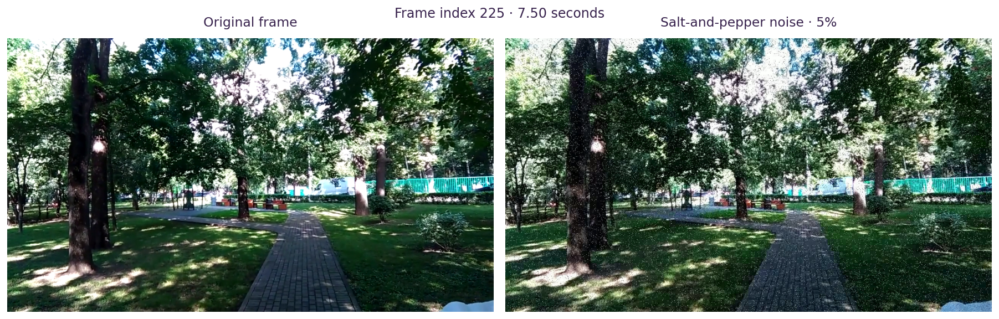

In [7]:
noisy_reader = cv2.VideoCapture(str(noisy_video_path))
noisy_reader.set(cv2.CAP_PROP_POS_FRAMES, sample_index)
success, noisy_sample = noisy_reader.read()
noisy_reader.release()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

for ax, frame, title in zip(
    axes,
    (original_sample, noisy_sample),
    ("Original frame", "Salt-and-pepper noise · 5%"),
):
    ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    ax.set_title(title, pad=12)
    ax.axis("off")

fig.suptitle(f"Frame index {sample_index} · {sample_index / fps:.2f} seconds", color="#38234d")
fig.tight_layout()
fig.savefig(output_dir / "01_original_and_noisy.png", dpi=160, bbox_inches="tight")
plt.show()

<h3 style="color:#8b5aab;">Report · Method and results</h3>
<table>
<thead><tr><th>Parameter</th><th>Value</th></tr></thead>
<tbody>
<tr><td>Noise density</td><td>5% of spatial pixel positions per frame</td></tr>
<tr><td>Pepper / salt split</td><td>2.5% black and 2.5% white</td></tr>
<tr><td>Selected positions per 1280 × 720 frame</td><td>46,080: 23,040 pepper and 23,040 salt</td></tr>
<tr><td>Random seed</td><td>42</td></tr>
<tr><td>Output</td><td>outputs/Q3/noisy_video.mp4</td></tr>
<tr><td>Frames / FPS / dimensions</td><td>450 / 30 / 1280 × 720 pixels</td></tr>
</tbody>
</table>
<p>The random generator selects distinct pixel positions in every frame. Sampling without replacement prevents overlap between salt and pepper selections and gives exactly the requested selected-position density. Seed 42 makes the random sequence reproducible when the noise-generation cells are rerun in order. The frame is copied before modification so the original sample is preserved.</p>
<p>Frames are read, modified, and written one at a time, avoiding the need to hold the complete video in memory. The writer uses the original frame rate and dimensions with the <code>mp4v</code> codec. Closing the writer with <code>release()</code> finalizes the MP4 file. The displayed comparison uses the same zero-based frame index, 225 (7.50 seconds), in both videos; the noisy sample is read back from the saved file.</p>
<p>The noisy frame contains scattered bright and dark dots across the scene. The 5% figure describes positions chosen for replacement; a naturally black or white pixel may already have its assigned value. MP4 encoding is lossy, so decoded noise pixels need not remain exactly 0 or 255, and compression can introduce small changes around them. The specified density and black/white split are applied before encoding.</p>
<p><b>Parameter choice.</b> The 5% density and equal salt/pepper split follow the assignment; seed 42 is an arbitrary fixed seed for reproducibility, not a tuned denoising parameter. The <code>mp4v</code> codec was chosen because it supports MP4 writing in this environment, while the original FPS and dimensions are retained as required.</p>

<hr>
<h2 style="color:#38234d;border-left:4px solid #8b5aab;padding-left:12px;">3.3 · Video denoising with the first filter</h2>
<p>We use a <b>3 × 3 median filter</b> on every frame of the saved noisy video. For each color channel, it replaces a pixel with the middle value among its nine neighboring values, including itself. An isolated black or white outlier is therefore usually replaced by a value closer to the surrounding surface, rather than being averaged into neighboring pixels.</p>

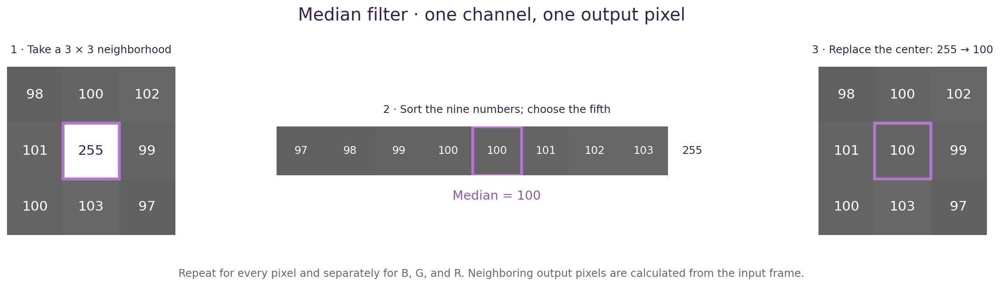

<p>The center is a white noise impulse (255), while its neighbors are near 100. Sorting the nine numbers puts 255 at the end. The fifth number is 100, so the output center becomes 100. Pepper noise (0) would fall at the opposite end and can be removed in the same way. This illustration is a synthetic example for one BGR channel, not an HSV value-channel calculation.</p>

In [8]:
median_kernel_size = 3
filtered_video_1_path = output_dir / "filtered_video_1.mp4"

noisy_reader = cv2.VideoCapture(str(noisy_video_path))
filtered_writer = cv2.VideoWriter(str(filtered_video_1_path), codec, fps, (frame_width, frame_height))
filtered_frame_count = 0

while True:
    success, noisy_frame = noisy_reader.read()
    if not success:
        break

    filtered_frame = cv2.medianBlur(noisy_frame, median_kernel_size)
    filtered_writer.write(filtered_frame)
    filtered_frame_count += 1

noisy_reader.release()
filtered_writer.release()

print(f"Filter: median; window = {median_kernel_size} × {median_kernel_size}")
print(f"Frames written: {filtered_frame_count}")
print(f"Saved: {filtered_video_1_path}")

Filter: median; window = 3 × 3
Frames written: 450
Saved: outputs\Q3\filtered_video_1.mp4


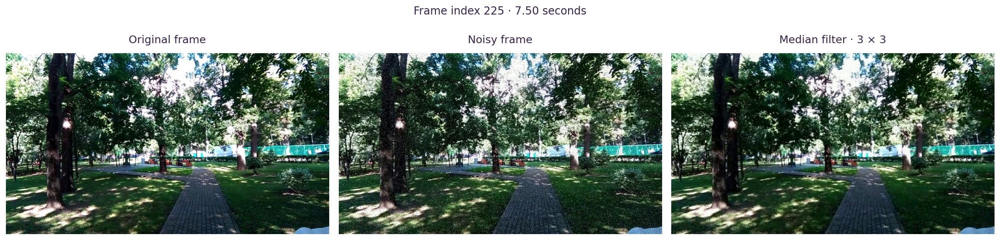

In [9]:
filtered_reader = cv2.VideoCapture(str(filtered_video_1_path))
filtered_reader.set(cv2.CAP_PROP_POS_FRAMES, sample_index)
success, filtered_sample = filtered_reader.read()
filtered_reader.release()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

for ax, frame, title in zip(
    axes,
    (original_sample, noisy_sample, filtered_sample),
    ("Original frame", "Noisy frame", "Median filter · 3 × 3"),
):
    ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    ax.set_title(title, pad=12)
    ax.axis("off")

fig.suptitle(f"Frame index {sample_index} · {sample_index / fps:.2f} seconds", color="#38234d")
fig.tight_layout()
fig.savefig(output_dir / "02_median_restoration.png", dpi=170, bbox_inches="tight")
plt.show()

<h3 style="color:#8b5aab;">Report · Filter selection and results</h3>
<table>
<thead><tr><th>Parameter</th><th>Value</th></tr></thead>
<tbody>
<tr><td>Filter</td><td>Median, applied independently to each frame</td></tr>
<tr><td>Window size</td><td>3 × 3 pixels</td></tr>
<tr><td>Implementation</td><td>cv2.medianBlur(frame, 3)</td></tr>
<tr><td>Input</td><td>outputs/Q3/noisy_video.mp4</td></tr>
<tr><td>Output</td><td>outputs/Q3/filtered_video_1.mp4</td></tr>
<tr><td>Frames / FPS / dimensions</td><td>450 / 30 / 1280 × 720 pixels</td></tr>
</tbody>
</table>
<p>A 3 × 3 window contains the current pixel and its eight immediate neighbors. For each BGR channel, the filter sorts those nine numbers and uses the fifth as the output value. An isolated 255 or 0 is usually at an end of the sorted list, so it does not become the output. A median is nonlinear because it selects a value by rank rather than computing a fixed weighted sum. The small window balances removal of isolated noise against loss of fine details.</p>
<p>The filter reads the saved noisy MP4, rather than adding a new random noise pattern. Each decoded frame is processed and written at the original frame rate and dimensions. The comparison displays the original, noisy, and decoded filtered frames at the same index, making the visible result representative of the saved output.</p>
<p>The restored frame shows fewer isolated bright and dark dots, while the larger scene structures remain recognizable. Some fine texture and narrow boundaries are softened. Groups of nearby noisy pixels can survive a small median window, and compression artifacts may remain because they are not limited to isolated black/white impulses. The filter uses only spatial neighbors within each frame; it does not use information from preceding or following frames.</p>
<p><b>Reference.</b> <a href="https://docs.opencv.org/4.13.0/d4/d13/tutorial_py_filtering.html">OpenCV’s smoothing tutorial</a> identifies the median filter as effective against salt-and-pepper noise. The 3 × 3 neighborhood is the smallest nontrivial odd square window, chosen to suppress isolated impulses while limiting damage to small details.</p>

<hr>
<h2 style="color:#38234d;border-left:4px solid #8b5aab;padding-left:12px;">3.4 · Comparison with a second denoising filter</h2>
<p>The second filter is a <b>3 × 3 Gaussian filter with σ = 1.0 pixels</b>. Each output channel value is a weighted average of its neighborhood, with more weight near the center. The weights are proportional to <b>exp[−(x² + y²)/(2σ²)]</b> and normalized to sum to 1. The window and σ define how widely neighboring pixels contribute. Both filters use 3 × 3 neighborhoods and independently process the same noisy video.</p>

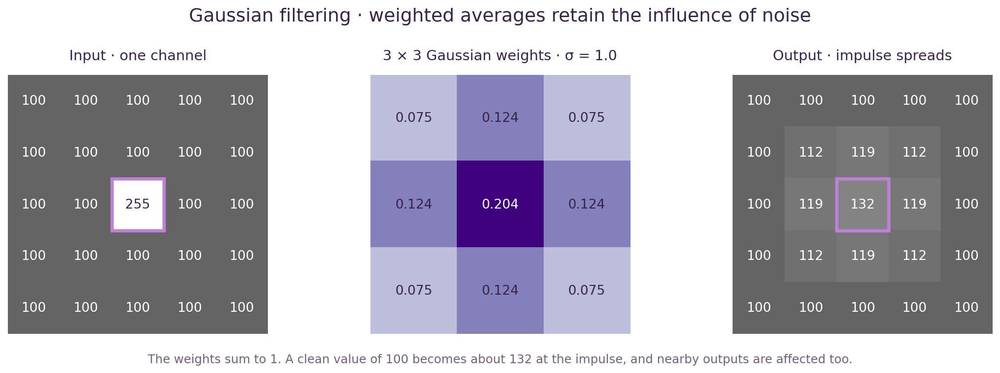

<p>This synthetic example shows one BGR channel. A white impulse of 255 sits on a surface whose values are 100. The Gaussian output is about 132 at the center, with smaller brightness increases around it. A median would return 100 at the center in this example. Gaussian smoothing weakens an impulse but spreads its influence because the weighted average still includes it.</p>

In [10]:
gaussian_kernel_size = (3, 3)
gaussian_sigma = 1.0
filtered_video_2_path = output_dir / "filtered_video_2.mp4"

noisy_reader = cv2.VideoCapture(str(noisy_video_path))
gaussian_writer = cv2.VideoWriter(
    str(filtered_video_2_path), codec, fps, (frame_width, frame_height)
)
gaussian_frame_count = 0

while True:
    success, noisy_frame = noisy_reader.read()
    if not success:
        break

    gaussian_frame = cv2.GaussianBlur(noisy_frame, gaussian_kernel_size, gaussian_sigma)
    gaussian_writer.write(gaussian_frame)
    gaussian_frame_count += 1

noisy_reader.release()
gaussian_writer.release()

print(f"Filter: Gaussian; window = 3 × 3; sigma = {gaussian_sigma:.1f}")
print(f"Frames written: {gaussian_frame_count}")
print(f"Saved: {filtered_video_2_path}")

Filter: Gaussian; window = 3 × 3; sigma = 1.0
Frames written: 450
Saved: outputs\Q3\filtered_video_2.mp4


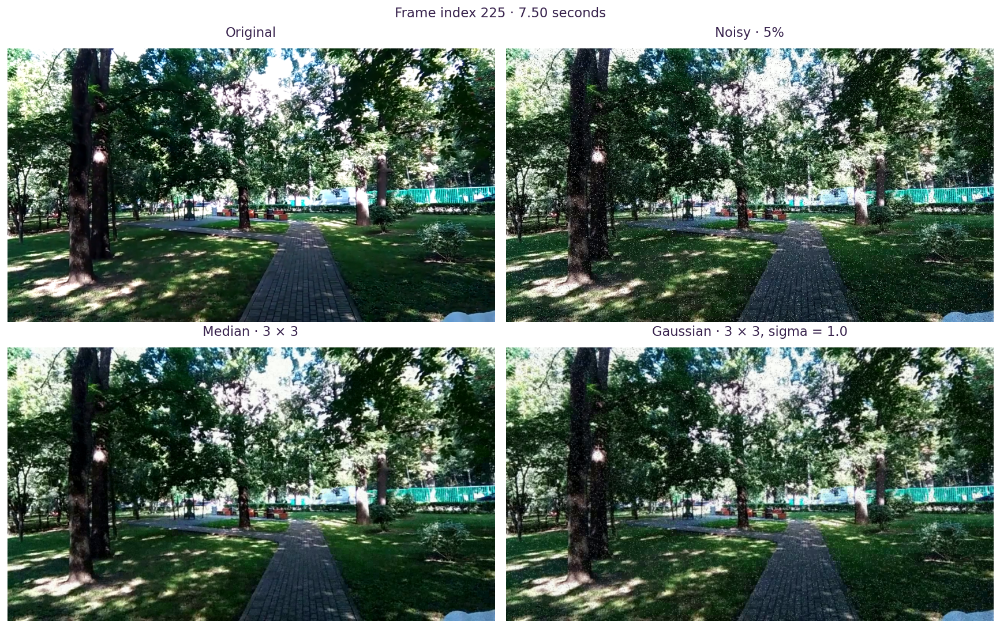

In [11]:
gaussian_reader = cv2.VideoCapture(str(filtered_video_2_path))
gaussian_reader.set(cv2.CAP_PROP_POS_FRAMES, sample_index)
success, gaussian_sample = gaussian_reader.read()
gaussian_reader.release()

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, frame, title in zip(
    axes.ravel(),
    (original_sample, noisy_sample, filtered_sample, gaussian_sample),
    ("Original", "Noisy · 5%", "Median · 3 × 3", "Gaussian · 3 × 3, sigma = 1.0"),
):
    ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    ax.set_title(title, pad=12)
    ax.axis("off")

fig.suptitle(f"Frame index {sample_index} · {sample_index / fps:.2f} seconds", color="#38234d")
fig.tight_layout()
fig.savefig(output_dir / "04_filter_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

<h3 style="color:#8b5aab;">Report · Method and comparison</h3>
<table>
<thead><tr><th>Property</th><th>Median</th><th>Gaussian</th></tr></thead>
<tbody>
<tr><td>Operation</td><td>Middle-ranked neighborhood value</td><td>Distance-weighted neighborhood average</td></tr>
<tr><td>Parameters</td><td>3 × 3 window</td><td>3 × 3 window, σ = 1.0 pixels</td></tr>
<tr><td>Input</td><td>noisy_video.mp4</td><td>noisy_video.mp4, independently</td></tr>
<tr><td>Output</td><td>filtered_video_1.mp4</td><td>filtered_video_2.mp4</td></tr>
</tbody>
</table>
<p>The Gaussian filter was selected to compare weighted averaging with the median's rank-based operation. Using the same window size limits the influence of neighborhood size, although the two methods do not have identical smoothing strength. The Gaussian output is expected to retain some impulse noise; that limitation is part of the comparison rather than evidence that the filter was applied incorrectly.</p>
<p><b>Which filter performed better at removing salt-and-pepper noise?</b><br>The median performs better in the inspected frames. An isolated 0 or 255 generally lies near an end of the sorted neighborhood, so the median can reject it when enough neighbors are uncorrupted. Gaussian averaging gives every location a positive weight and does not test whether a pixel is an outlier. A corrupted value therefore affects its own output and nearby outputs. For example, with a center weight of about 0.204, changing a center value from 100 to 255 adds about 31.6 to its filtered result, even when every neighbor remains 100. Noise becomes weaker but spreads into small patches. Averaging is more suitable for small distributed fluctuations than for these occasional extreme replacements. A larger Gaussian window could suppress the dots further, but would also blur more detail; it does not solve the lack of outlier rejection.</p>
<p><b>Which filter better preserved image details and object boundaries?</b><br>For this corruption, the median gives a cleaner view of larger structures such as tree trunks and pavement boundaries because it removes isolated impulses without averaging across every boundary. It can still erase thin features and small textures. Gaussian averaging mixes values across edges and leaves noise-influenced patches, which makes fine foliage and pavement details less distinct. Some texture may remain visible in the Gaussian result, but it is harder to distinguish from residual noise.</p>
<p><b>Did the filters blur any regions? Why?</b><br>Yes. Gaussian averaging reduces differences between neighboring pixels, softening edges and fine textures. Median filtering can also soften details when a small structure differs from most of the pixels in its window. Both therefore trade some detail for smoothing, but the median removes the specified impulse noise more effectively. Compression artifacts and groups of corrupted pixels may remain after either method.</p>
<p><b>Gaussian parameters.</b> The 3 × 3 window matches the median neighborhood, and σ = 1.0 gives the center greater influence while still using all eight neighbors; this provides a local weighted-average baseline without a wider blur. This is a controlled comparison rather than an optimum for impulse noise; <a href="https://docs.opencv.org/4.13.0/d4/d13/tutorial_py_filtering.html">OpenCV’s smoothing tutorial</a> describes the Gaussian and median operations.</p>

<hr>
<h2 style="color:#38234d;border-left:4px solid #8b5aab;padding-left:12px;">3.5 · Frame comparisons and analysis</h2>
<p>We compare the same frame indices across the original, noisy, median-filtered, and Gaussian-filtered videos. Indices 45, 225, and 405 sample the beginning, middle, and end of the 450-frame video, at 1.50, 7.50, and 13.50 seconds. Every displayed frame is decoded from its saved video.</p>

In [12]:
comparison_indices = [int(0.1 * frame_count), frame_count // 2, int(0.9 * frame_count)]
comparison_names = ("Original", "Noisy · 5%", "Median · 3 × 3", "Gaussian · 3 × 3")
comparison_paths = (video_path, noisy_video_path, filtered_video_1_path, filtered_video_2_path)
comparison_frames = []

for path in comparison_paths:
    reader = cv2.VideoCapture(str(path))
    frames = []

    for index in comparison_indices:
        reader.set(cv2.CAP_PROP_POS_FRAMES, index)
        success, frame = reader.read()
        frames.append(frame)

    reader.release()
    comparison_frames.append(frames)

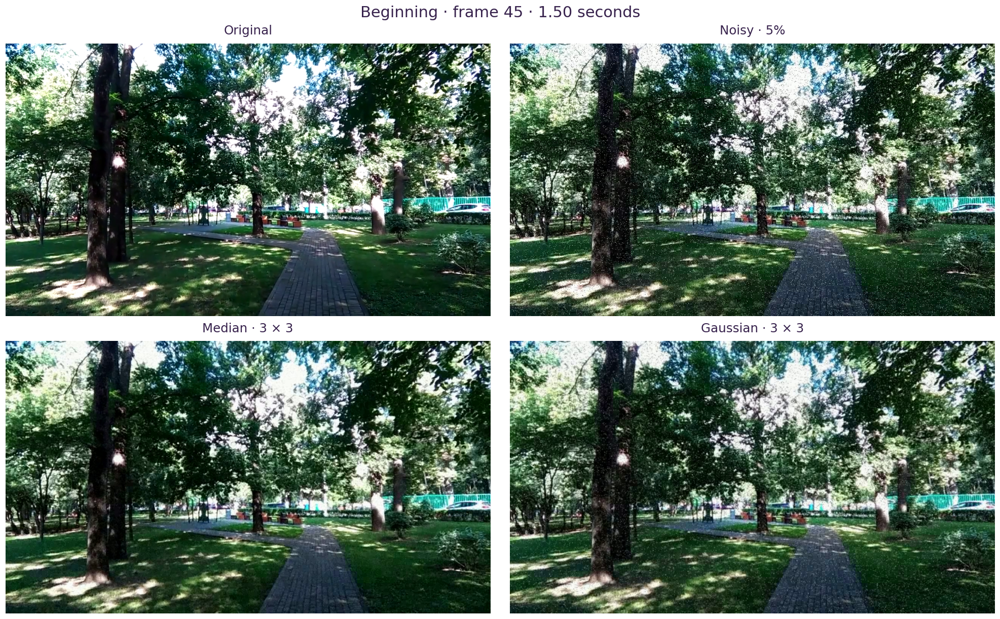

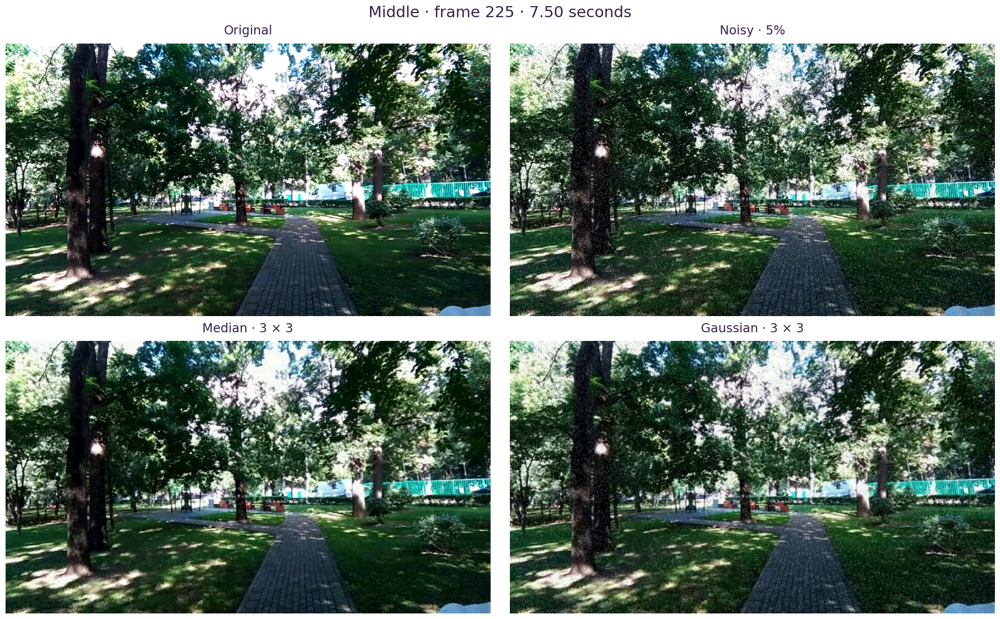

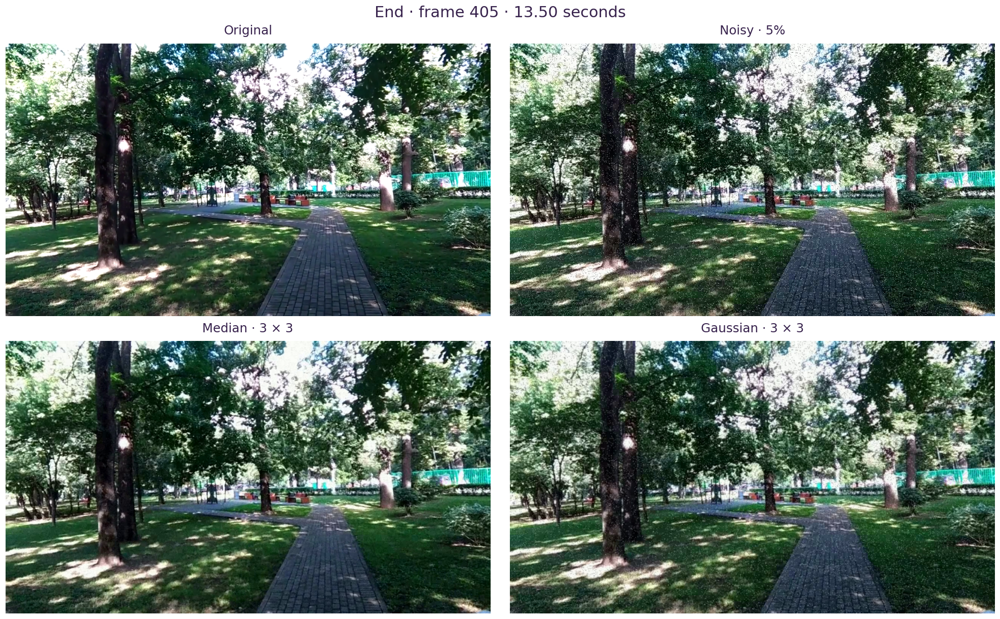

In [13]:
comparison_stages = ("Beginning", "Middle", "End")

for row, (stage, index) in enumerate(zip(comparison_stages, comparison_indices)):
    fig, axes = plt.subplots(2, 2, figsize=(18, 11), layout="constrained")

    for column, (ax, name) in enumerate(zip(axes.ravel(), comparison_names)):
        frame = comparison_frames[column][row]
        ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        ax.set_title(name, fontsize=16, pad=12)
        ax.axis("off")

    fig.suptitle(f"{stage} · frame {index} · {index / fps:.2f} seconds", color="#38234d", fontsize=20)
    fig.savefig(output_dir / f"{6 + row:02d}_comparison_{stage.lower()}.png", dpi=170, bbox_inches="tight")
    plt.show()

In [14]:
video_properties = []

for name, path in zip(comparison_names, comparison_paths):
    reader = cv2.VideoCapture(str(path))
    saved_frames = int(reader.get(cv2.CAP_PROP_FRAME_COUNT))
    saved_fps = reader.get(cv2.CAP_PROP_FPS)
    saved_width = int(reader.get(cv2.CAP_PROP_FRAME_WIDTH))
    saved_height = int(reader.get(cv2.CAP_PROP_FRAME_HEIGHT))
    reader.release()

    saved_duration = saved_frames / saved_fps
    video_properties.append((name, saved_frames, saved_fps, saved_width, saved_height, saved_duration))
    print(f"{name:<20} Frames: {saved_frames}; FPS: {saved_fps:.2f}; "
          f"Size: {saved_width} × {saved_height}; Duration: {saved_duration:.2f} s")

Original             Frames: 450; FPS: 30.00; Size: 1280 × 720; Duration: 15.00 s
Noisy · 5%           Frames: 450; FPS: 30.00; Size: 1280 × 720; Duration: 15.00 s
Median · 3 × 3       Frames: 450; FPS: 30.00; Size: 1280 × 720; Duration: 15.00 s
Gaussian · 3 × 3     Frames: 450; FPS: 30.00; Size: 1280 × 720; Duration: 15.00 s


<h3 style="color:#8b5aab;">Report · Analysis across the video</h3>
<p><b>Environmental details.</b> Across all three sampled times, noise adds bright and dark speckles to the grass, foliage, tree trunks, and path. The median removes most isolated speckles, making broad surfaces easier to read. Fine leaves and grass texture become somewhat smoother. The Gaussian reduces individual noise peaks but leaves a mottled pattern; its averaging also softens the pavement texture and small branches. The similar pattern across the three times supports the comparison beyond a single middle frame.</p>
<p><b>Object boundaries.</b> The outlines of the large foreground tree and the edges of the walkway remain recognizable after both filters. The median generally gives cleaner boundaries under impulse noise. Gaussian averaging mixes neighboring regions, reducing the sharpness of narrow edges, while residual impulses can resemble small details. Neither method recovers all information lost through corruption and MP4 compression.</p>
<p><b>Moving objects.</b> The samples include distant road activity, including a vehicle near the right side of the beginning frame. Broad object shapes remain visible, but small boundary details are affected by spatial smoothing and residual noise. Both filters process each frame independently: they use no motion estimation or temporal averaging, so they do not create cross-frame ghost trails through temporal blending. They also cannot repair motion blur already present in the source. Three still frames support inspection of appearance, but do not fully assess temporal flicker or track an object's motion.</p>
<h3 style="color:#8b5aab;">Report · Output properties</h3>
<table>
<thead><tr><th>Video</th><th>Frames</th><th>FPS</th><th>Width × height</th><th>Duration</th></tr></thead>
<tbody>
<tr><td>Original</td><td>450</td><td>30.00</td><td>1280 × 720</td><td>15.00 s</td></tr>
<tr><td>Noisy</td><td>450</td><td>30.00</td><td>1280 × 720</td><td>15.00 s</td></tr>
<tr><td>Median</td><td>450</td><td>30.00</td><td>1280 × 720</td><td>15.00 s</td></tr>
<tr><td>Gaussian</td><td>450</td><td>30.00</td><td>1280 × 720</td><td>15.00 s</td></tr>
</tbody>
</table>
<p>The properties read back from the saved files confirm that every output preserves the original frame rate and spatial dimensions. All videos also retain 450 frames and a duration of 15 seconds. The frame comparisons therefore use corresponding positions in time, and the filtering does not change playback speed.</p>
<p><b>Sampling choice.</b> The 10%, 50%, and 90% positions spread the three required samples across the video’s duration, with the same frame indices used in every version for a fair visual comparison.</p>